
Cancer dataset: SVM kernels
     model  accuracy  precision   recall       f1
SVM linear  0.964912   0.936170 0.977778 0.956522
   SVM rbf  0.964912   0.955556 0.955556 0.955556
  SVM poly  0.885965   1.000000 0.711111 0.831169


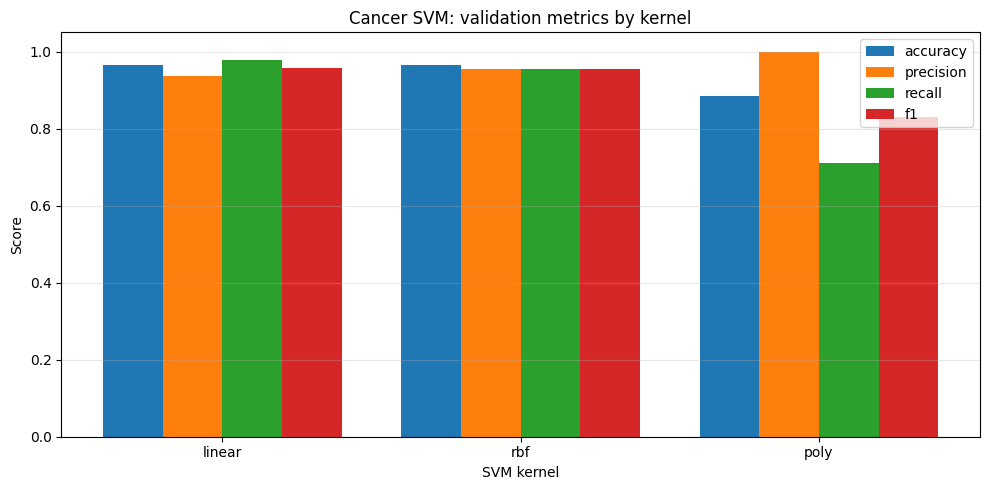

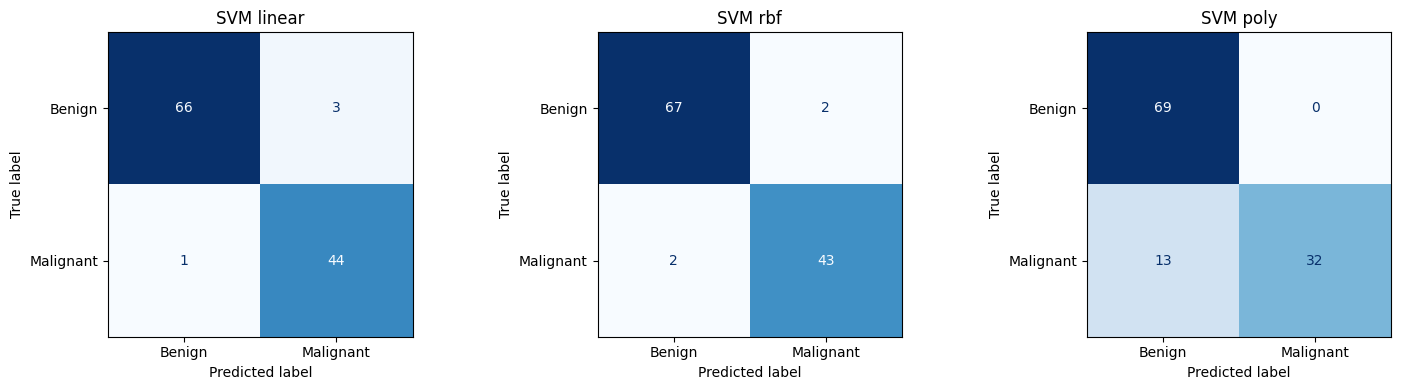

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
)

data = pd.read_csv("/content/Cancer.csv")
data = data.drop(columns=[col for col in data.columns if "Unnamed" in col], errors="ignore")

y = data["diagnosis"].map({"M": 1, "B": 0}).astype(int).values
X = data.drop(columns=["id", "diagnosis"]).values
m = len(y)

np.random.seed(7)
indices = np.random.permutation(m)
split_index = int(0.8 * m)

train_indices = indices[:split_index]
validation_indices = indices[split_index:]

X_train = X[train_indices]
y_train = y[train_indices]
X_validation = X[validation_indices]
y_validation = y[validation_indices]

X_train_mean = X_train.mean(axis=0)
X_train_std = X_train.std(axis=0)
X_train_std[X_train_std == 0.0] = 1.0

X_train = (X_train - X_train_mean) / X_train_std
X_validation = (X_validation - X_train_mean) / X_train_std

def svm_evaluate(kernel, X_train, y_train, X_validation, y_validation, **kwargs):
    model = SVC(kernel=kernel, **kwargs)
    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)

    accuracy = accuracy_score(y_validation, predictions)
    precision = precision_score(y_validation, predictions, zero_division=0)
    recall = recall_score(y_validation, predictions, zero_division=0)
    f1 = f1_score(y_validation, predictions, zero_division=0)
    cm = confusion_matrix(y_validation, predictions)

    return model, predictions, accuracy, precision, recall, f1, cm

kernels = ["linear", "rbf", "poly"]
svm_results = {}

for kernel in kernels:
    model, predictions, accuracy, precision, recall, f1, cm = svm_evaluate(
        kernel,
        X_train,
        y_train,
        X_validation,
        y_validation
    )

    svm_results[kernel] = {
        "model": model,
        "predictions": predictions,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "cm": cm,
    }

# print comparison table
comparison_rows = []

for kernel in kernels:
    comparison_rows.append({
        "model": f"SVM {kernel}",
        "accuracy": svm_results[kernel]["accuracy"],
        "precision": svm_results[kernel]["precision"],
        "recall": svm_results[kernel]["recall"],
        "f1": svm_results[kernel]["f1"],
    })

comparison_df = pd.DataFrame(comparison_rows)
print("\nCancer dataset: SVM kernels")
print(comparison_df.sort_values("accuracy", ascending=False).to_string(index=False))

# plot accuracy, precision, recall, F1 for SVM kernels
metrics_to_plot = ["accuracy", "precision", "recall", "f1"]
x = np.arange(len(kernels))
width = 0.2

plt.figure(figsize=(10, 5))

for i, metric in enumerate(metrics_to_plot):
    plt.bar(
        x + i * width,
        [svm_results[k][metric] for k in kernels],
        width,
        label=metric
    )

plt.xticks(x + width * 1.5, kernels)
plt.ylim(0, 1.05)
plt.xlabel("SVM kernel")
plt.ylabel("Score")
plt.title("Cancer SVM: validation metrics by kernel")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# confusion matrix for each SVM kernel
fig, axes = plt.subplots(1, len(kernels), figsize=(5 * len(kernels), 4))

for ax, kernel in zip(axes, kernels):
    cm = svm_results[kernel]["cm"]
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )
    disp.plot(cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"SVM {kernel}")

plt.tight_layout()
plt.show()


Housing dataset: SVR kernels
     model         rmse          mae       r2
   SVR rbf 1.075295e+06 7.930556e+05 0.665329
SVR linear 1.077918e+06 7.589564e+05 0.663694
  SVR poly 1.708366e+06 1.121561e+06 0.155256


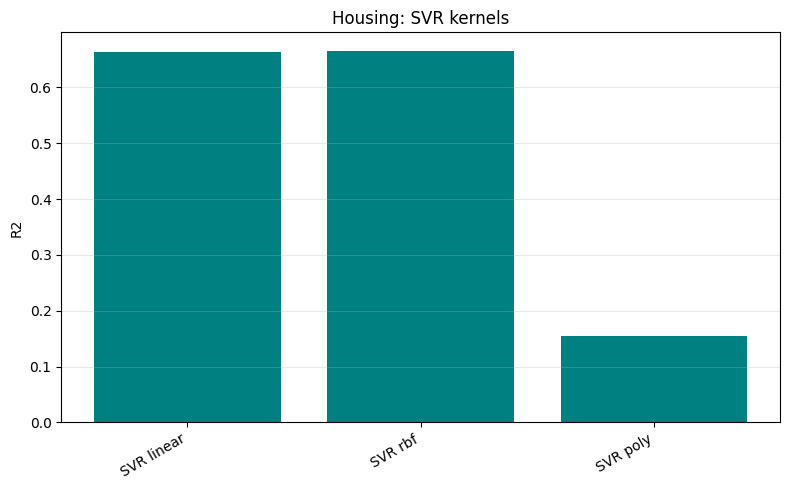

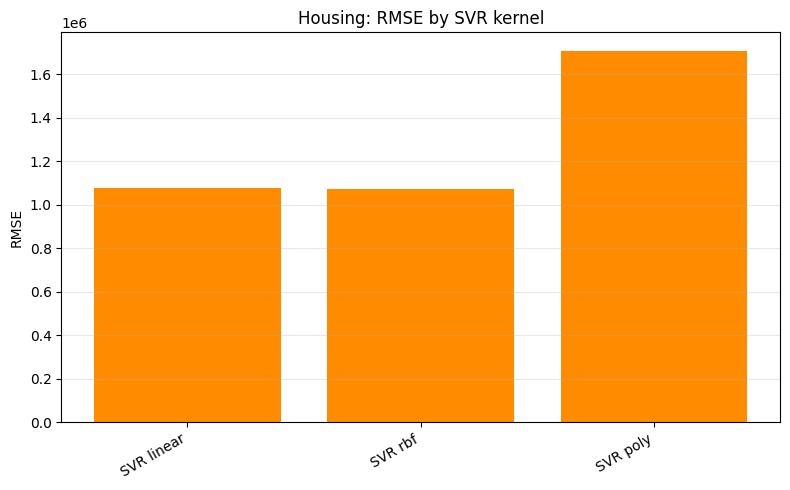

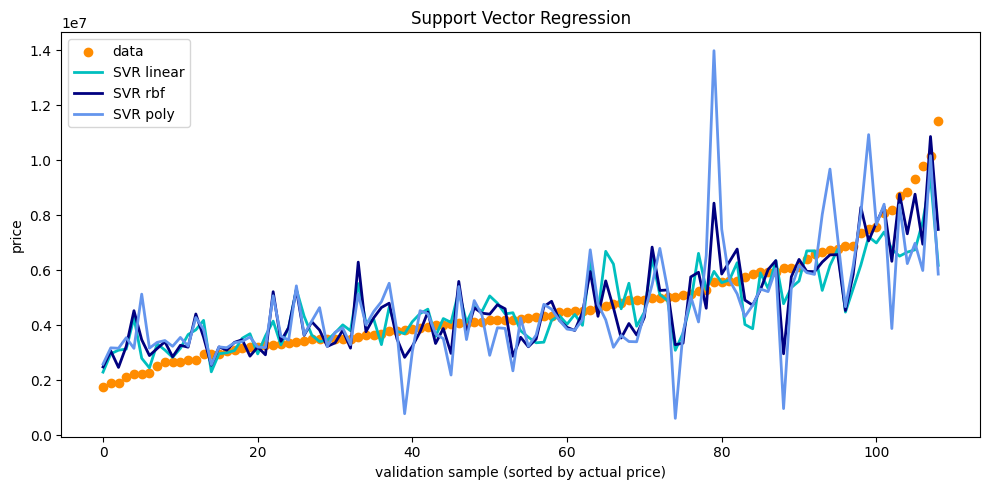

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.svm import SVR

data_housing = pd.read_csv("/content/Housing.csv")
data_housing.columns = data_housing.columns.str.lower()

feature_cols = ["area", "bedrooms", "bathrooms", "stories", "mainroad",
                "guestroom", "basement", "hotwaterheating", "airconditioning",
                "parking", "prefarea"]

target_col = "price"

categorical_cols = ["mainroad", "guestroom", "basement",
                    "hotwaterheating", "airconditioning", "prefarea"]

for col in categorical_cols:
    if data_housing[col].dtype == object:
        data_housing[col] = (
            data_housing[col].astype(str).str.lower().map({"yes": 1, "no": 0})
        )

X = data_housing[feature_cols].values
y = data_housing[target_col].values
m = len(y)

np.random.seed(7)
indices = np.random.permutation(m)
split_index = int(0.8 * m)

train_indices = indices[:split_index]
validation_indices = indices[split_index:]

X_train = X[train_indices]
y_train = y[train_indices]
X_validation = X[validation_indices]
y_validation = y[validation_indices]

X_train_mean = X_train.mean(axis=0)
X_train_std = X_train.std(axis=0)
X_train_std[X_train_std == 0.0] = 1.0

X_train = (X_train - X_train_mean) / X_train_std
X_validation = (X_validation - X_train_mean) / X_train_std

y_train_mean = y_train.mean()
y_train_std = y_train.std()

y_train_scaled = (y_train - y_train_mean) / y_train_std

def svr_evaluate(kernel, X_train, y_train_scaled, X_validation, y_validation,
                 y_train_mean, y_train_std, **kwargs):
    model = SVR(kernel=kernel, **kwargs)
    model.fit(X_train, y_train_scaled)
    predictions_scaled = model.predict(X_validation)
    predictions = predictions_scaled * y_train_std + y_train_mean

    mse = np.mean((y_validation - predictions) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_validation - predictions))

    ss_res = np.sum((y_validation - predictions) ** 2)
    ss_tot = np.sum((y_validation - y_validation.mean()) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else 0.0

    return model, predictions, rmse, mae, r2

kernels = ["linear", "rbf", "poly"]
svr_results = {}

for kernel in kernels:
    model, predictions, rmse, mae, r2 = svr_evaluate(
        kernel,
        X_train,
        y_train_scaled,
        X_validation,
        y_validation,
        y_train_mean,
        y_train_std,
        C=10.0,
        epsilon=0.1
    )

    svr_results[kernel] = {
        "model": model,
        "predictions": predictions,
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
    }

# print comparison table
comparison_rows = []

for kernel in kernels:
    comparison_rows.append({
        "model": f"SVR {kernel}",
        "rmse": svr_results[kernel]["rmse"],
        "mae": svr_results[kernel]["mae"],
        "r2": svr_results[kernel]["r2"],
    })

comparison_df = pd.DataFrame(comparison_rows)
print("\nHousing dataset: SVR kernels")
print(comparison_df.sort_values("rmse").to_string(index=False))

# plot R2 across SVR kernels
models = [f"SVR {k}" for k in kernels]
r2_scores = [svr_results[k]["r2"] for k in kernels]

plt.figure(figsize=(8, 5))
plt.bar(models, r2_scores, color="teal")
plt.ylabel("R2")
plt.title("Housing: SVR kernels")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# plot RMSE across SVR kernels
rmse_scores = [svr_results[k]["rmse"] for k in kernels]

plt.figure(figsize=(8, 5))
plt.bar(models, rmse_scores, color="darkorange")
plt.ylabel("RMSE")
plt.title("Housing: RMSE by SVR kernel")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# plot SVR predictions vs actual for each kernel
sample_order = np.argsort(y_validation)
x_axis = np.arange(len(y_validation))

kernel_colors = {
    "linear": "c",
    "rbf": "navy",
    "poly": "cornflowerblue",
}

lw = 2

plt.figure(figsize=(10, 5))
plt.scatter(x_axis, y_validation[sample_order],
            color="darkorange", label="data")

for kernel in kernels:
    plt.plot(x_axis,
             svr_results[kernel]["predictions"][sample_order],
             color=kernel_colors[kernel], lw=lw,
             label=f"SVR {kernel}")

plt.xlabel("validation sample (sorted by actual price)")
plt.ylabel("price")
plt.title("Support Vector Regression")
plt.legend()
plt.tight_layout()
plt.show()